<a href="https://colab.research.google.com/github/mahamtaqi3-cloud/WntA-CRE-Explorer-Visualizing-Regulatory-Conservation-in-Butterfly-Wing-Patterns/blob/main/WntA_CRE_Explorer_Visualizing_Regulatory_Conservation_in_Butterfly_Wing_Patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

WntA CRE Explorer: Visualizing Regulatory Conservation in Butterfly Wing Patterns


Setting up the Environment

In [6]:
import numpy as np                     # tool for numbers
import matplotlib.pyplot as plt        # tool for drawing charts
from sklearn.ensemble import RandomForestClassifier  # the ML model

np.random.seed(42)   # makes the "random" numbers the same each time

Conservation of regulatory elements

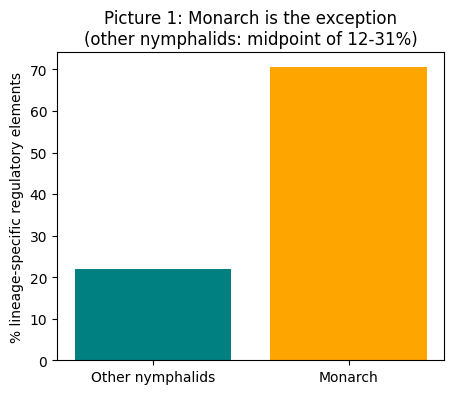

In [8]:
groups = ["Other nymphalids", "Monarch"]
lineage_specific = [22, 70.6]   # % of regulatory elements that are lineage-specific

plt.figure(figsize=(5, 4))
plt.bar(groups, lineage_specific, color=["teal", "orange"])
plt.ylabel("% lineage-specific regulatory elements")
plt.title("Picture 1: Monarch is the exception\n (other nymphalids: midpoint of 12-31%)")
plt.show()

One deletion, many wing regions (simulated)

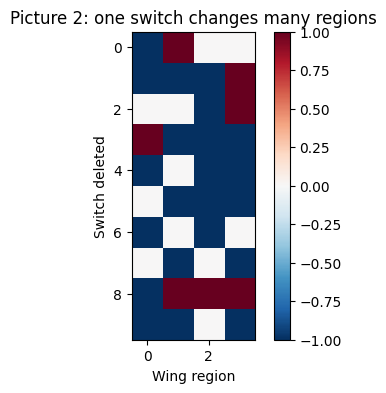

In [9]:
# 10 switches (rows) x 4 wing regions (columns)
# -1 = pattern lost, +1 = pattern grows, 0 = no change
effects = np.random.choice([-1, 0, 1], size=(10, 4), p=[0.5, 0.3, 0.2])

plt.figure(figsize=(5, 4))
plt.imshow(effects, cmap="RdBu_r")
plt.xlabel("Wing region")
plt.ylabel("Switch deleted")
plt.title("Picture 2: one switch changes many regions")
plt.colorbar()
plt.show()

Can a model predict the effect? (toy ML, simulated)

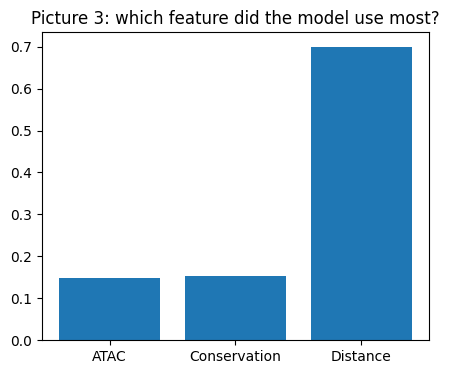

In [10]:
# Made-up facts about 200 regulatory elements
atac = np.random.rand(200)           # how open the DNA is
conservation = np.random.rand(200)   # how conserved it is
distance = np.random.rand(200)       # distance from the gene

facts = np.column_stack([atac, conservation, distance])

# Made-up answer key: 1 = pattern grows, 0 = pattern lost
answer = (distance + np.random.rand(200) * 0.3 > 0.6).astype(int)

model = RandomForestClassifier()
model.fit(facts, answer)             # the model learns from the data

plt.figure(figsize=(5, 4))
plt.bar(["ATAC", "Conservation", "Distance"], model.feature_importances_)
plt.title("Picture 3: which feature did the model use most?")
plt.show()

## Next steps
- Replace simulated features with real ATAC-seq and Hi-C features (BioProject PRJNA695303)
- Use phenotype labels from the paper's Data S1
- Try sequence-based models, and validate top predictions with CRISPR